# 2. Trading one pair

Given a pair, three things turn it into a strategy:

1. a **signal**: how far the spread is from its mean, in standard deviations;
2. a **rule**: when to enter, exit and give up;
3. an **accounting** of returns and costs that never uses information from the future.

This notebook builds them, first on simulated data and then on a real pair, and compares a fixed hedge ratio with one updated by a Kalman filter.

In [1]:
import sys
sys.path.insert(0, "..")  # make the `pairs` package importable from the notebooks folder

from dataclasses import replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pairs import (Rule, Settings, benjamini_hochberg, candidate_pairs, engle_granger, kalman_hedge, load_prices, metrics,
                   positions_from_zscore, run_backtest, scan_pairs, sector_of, simulate_pair, split_benchmark, trade_pair)
from pairs.plotting import use_style, BLUE, ORANGE, AQUA, YELLOW, MUTED, INK_SOFT, GRID

use_style()
pd.options.display.float_format = "{:.3f}".format

prices, benchmark = split_benchmark(load_prices("../data/prices.csv"))
log_prices = np.log(prices)
print(f"{prices.shape[1]} stocks, {len(prices):,} trading days, {prices.index[0]:%Y-%m-%d} to {prices.index[-1]:%Y-%m-%d}")

104 stocks, 4,243 trading days, 2010-01-04 to 2026-11-13


## 2.1 The trading rule

* **Enter** when the spread is more than 2 standard deviations from its mean: short the spread if it is too high, long if too low.
* **Exit** when it is back within 0.5 standard deviations.
* **Stop** if it goes beyond 4 standard deviations: the relation may have broken. Stay out until the spread is back to normal.

"Long the spread" means buying $Y$ and selling $\beta$ times as much $X$, scaled so that the total amount committed is 1.

7 trades, in the market 16% of the time, total return 14.8%


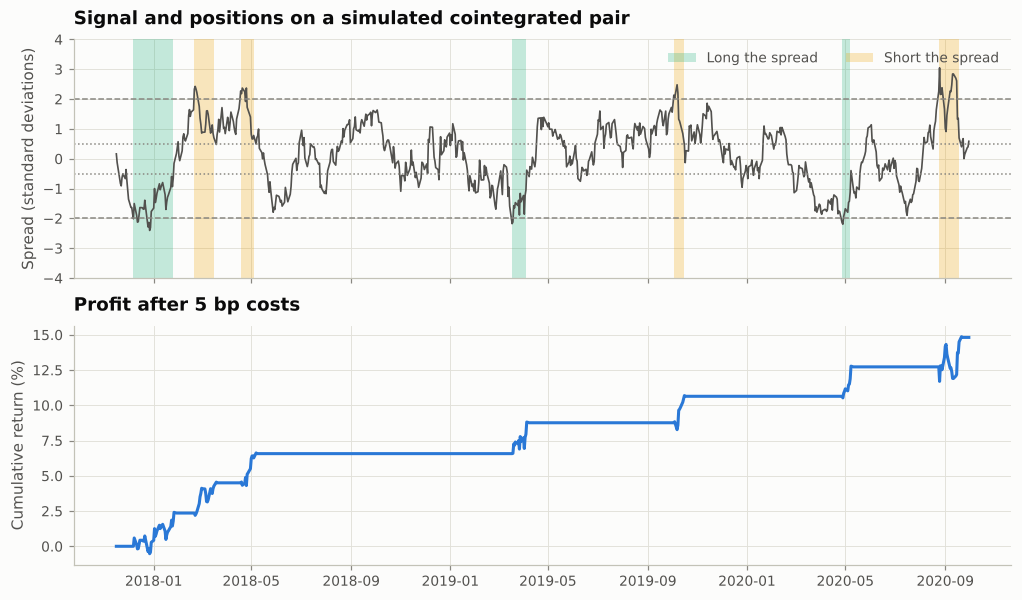

In [2]:
pair = simulate_pair(n_days=1500, beta=1.3, half_life=15, seed=2)
formation, trading = pair.iloc[:750], pair.iloc[750:]
trade = trade_pair(formation, trading, method="static", rule=Rule(entry=2.0, exit=0.5, stop=4.0), cost_bps=5)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True)
top.plot(trade.z_score.index, trade.z_score, color=INK_SOFT, linewidth=1.1)
for level, style in [(2, "--"), (-2, "--"), (0.5, ":"), (-0.5, ":")]:
    top.axhline(level, color=MUTED, linestyle=style, linewidth=1.0)
for sign, color, label in [(1.0, AQUA, "Long the spread"), (-1.0, YELLOW, "Short the spread")]:
    top.fill_between(trade.position.index, -4, 4, where=(trade.position == sign).to_numpy(), color=color, alpha=0.25,
                     linewidth=0, label=label)
top.set_ylim(-4, 4); top.set_ylabel("Spread (standard deviations)")
top.set_title("Signal and positions on a simulated cointegrated pair"); top.legend(loc="upper right", ncol=2)
bottom.plot(trade.returns.index, 100 * trade.returns.cumsum(), color=BLUE)
bottom.set_ylabel("Cumulative return (%)"); bottom.set_title("Profit after 5 bp costs");
print(f"{trade.n_trades} trades, in the market {trade.days_in_market:.0%} of the time, total return {trade.returns.sum():.1%}")

On a pair that really is cointegrated, the rule earns a steady profit: each trade captures the return of the spread to its mean.

## 2.2 No information from the future

Two precautions, both tested in the test suite:

* the hedge ratio, the mean and the standard deviation of the spread come from the **formation** period only;
* a position decided at the close of day $t$ earns the returns of day $t+1$ onwards, never the return of day $t$.

A direct check: change the prices from some date on, and verify that nothing before that date changes.

In [3]:
altered = trading.copy()
altered.iloc[300:] = altered.iloc[300:] * [1.3, 0.8]     # rewrite the future
changed = trade_pair(formation, altered, method="static", cost_bps=5)
print("Positions before the change identical:", trade.position.iloc[:300].equals(changed.position.iloc[:300]))
print("Returns before the change identical:  ", np.allclose(trade.returns.iloc[:300], changed.returns.iloc[:300]))



Positions before the change identical: True
Returns before the change identical:   True


**What a look-ahead bug costs.** A very common mistake is to standardise the spread with the mean and standard deviation of the period being traded, instead of those of the formation period. The spread then crosses its "mean" by construction. The comparison below trades one same-sector pair in four, over every six-month period, both ways:

In [4]:
from pairs.cointegration import ols_hedge_ratio
from pairs.strategy import pair_returns

honest, cheating = [], []
for start in range(504, len(prices) - 126, 126):
    formation_window, trading_window = prices.iloc[start - 504:start], prices.iloc[start - 1:start + 126]
    simple = trading_window.pct_change().fillna(0.0)
    for y, x in candidate_pairs(prices.columns)[::4]:
        beta, alpha = ols_hedge_ratio(np.log(formation_window[y].to_numpy()), np.log(formation_window[x].to_numpy()))
        past = np.log(formation_window[y].to_numpy()) - beta * np.log(formation_window[x].to_numpy()) - alpha
        spread = np.log(trading_window[y].to_numpy()) - beta * np.log(trading_window[x].to_numpy()) - alpha
        signals = {"honest": spread / past.std(ddof=1),                           # scaled with the past only
                   "cheating": (spread - spread.mean()) / spread.std(ddof=1)}      # scaled with the period being traded
        for name, store in (("honest", honest), ("cheating", cheating)):
            store.append(pair_returns(simple[y].to_numpy(), simple[x].to_numpy(), beta,
                                      positions_from_zscore(signals[name]), cost_bps=5).sum())

pd.DataFrame({"Return per pair, annualised": [2 * np.mean(honest), 2 * np.mean(cheating)],
              "Profitable pair-periods": [np.mean(np.array(honest) > 0), np.mean(np.array(cheating) > 0)]},
             index=["Past mean and standard deviation", "Mean and standard deviation of the traded period"]).style.format("{:.1%}")

,"Return per pair, annualised",Profitable pair-periods
Past mean and standard deviation,-0.7%,33.6%
Mean and standard deviation of the traded period,10.1%,69.5%


Same pairs, same rule, same costs: the only difference is two numbers taken from the future, and a strategy that loses money looks like one that earns 10% a year with seven winning trades in ten. This is why the absence of look-ahead is tested explicitly, by rewriting future prices and checking that nothing earlier changes.

## 2.3 A hedge ratio that adapts: the Kalman filter

A regression gives one hedge ratio for the whole formation period. If the relation drifts, a fixed ratio produces a spread that drifts too. The Kalman filter treats $\beta_t$ and $\alpha_t$ as hidden states following a random walk:

$$\theta_t = \theta_{t-1} + w_t, \qquad \log Y_t = \beta_t \log X_t + \alpha_t + v_t .$$

Each day it predicts $\log Y_t$ from yesterday's state, measures the error $e_t$, and corrects the state by a fraction of that error (the Kalman gain). The error and its predicted standard deviation $\sqrt{Q_t}$ are known before day $t$'s update, so $e_t/\sqrt{Q_t}$ is a signal with no look-ahead.

A simulated pair whose true hedge ratio drifts from 1.0 to 1.6:

Mean absolute spread over the last 500 days: fixed 1.834, Kalman 0.035


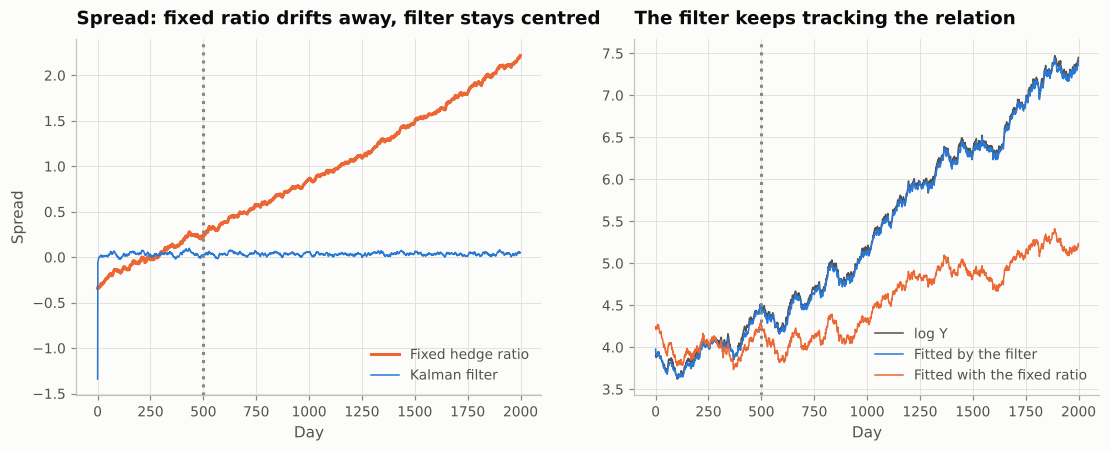

In [5]:
rng = np.random.default_rng(5)
n = 2000
log_x = np.log(50) + np.cumsum(0.015 * rng.standard_normal(n))
true_beta = np.linspace(1.0, 1.6, n)
noise = np.zeros(n)
for t in range(1, n):
    noise[t] = 0.955 * noise[t - 1] + 0.006 * rng.standard_normal()
log_y = true_beta * log_x + noise

fixed_beta = np.polyfit(log_x[:500], log_y[:500], 1)[0]
filtered = kalman_hedge(log_y, log_x, observation_variance=noise.var(), adaptation_days=120,
                        initial_state=(fixed_beta, 0.0), initial_variance=noise.var())
fitted = filtered.beta * log_x + filtered.alpha

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))
left.plot(log_y - fixed_beta * log_x - np.mean(log_y[:500] - fixed_beta * log_x[:500]), color=ORANGE, label="Fixed hedge ratio")
left.plot(filtered.error, color=BLUE, linewidth=1.0, label="Kalman filter")
left.axvline(500, color=MUTED, linestyle=":")
left.set_xlabel("Day"); left.set_ylabel("Spread"); left.set_title("Spread: fixed ratio drifts away, filter stays centred"); left.legend()
right.plot(log_y, color=INK_SOFT, linewidth=1.0, label="log Y")
right.plot(fitted, color=BLUE, linewidth=1.0, label="Fitted by the filter")
right.plot(fixed_beta * log_x + np.mean(log_y[:500] - fixed_beta * log_x[:500]), color=ORANGE, linewidth=1.0, label="Fitted with the fixed ratio")
right.axvline(500, color=MUTED, linestyle=":")
right.set_xlabel("Day"); right.set_title("The filter keeps tracking the relation"); right.legend();
print(f"Mean absolute spread over the last 500 days: fixed {np.abs(log_y - fixed_beta * log_x - np.mean(log_y[:500] - fixed_beta * log_x[:500]))[-500:].mean():.3f}, "
      f"Kalman {np.abs(filtered.error)[-500:].mean():.3f}")

With a relation that changes, the fixed-ratio spread stops returning to zero after the formation period (left of the dotted line), while the filter's forecast error stays centred.

**The price of adapting.** The filter cannot tell a temporary deviation of the spread (which we want to trade) from a permanent change of the relation (which it should absorb). The `adaptation_days` parameter sets how fast it follows the data. If it adapts as fast as the spread reverts, it explains every deviation away and nothing is left to trade:

In [6]:
rows = []
for days in [10, 30, 60, 120, 250, 1000]:
    outcomes = []
    for seed in range(20):
        sample = simulate_pair(n_days=1500, beta=1.3, half_life=15, seed=100 + seed)
        outcomes.append(trade_pair(sample.iloc[:750], sample.iloc[750:], "kalman", cost_bps=5, adaptation_days=days))
    rows.append({"Adaptation time (days)": days, "Trades per pair": np.mean([o.n_trades for o in outcomes]),
                 "Std of the signal": np.mean([o.z_score.std() for o in outcomes]),
                 "Mean total return": np.mean([o.returns.sum() for o in outcomes])})
static = [trade_pair(simulate_pair(n_days=1500, beta=1.3, half_life=15, seed=100 + s).iloc[:750],
                     simulate_pair(n_days=1500, beta=1.3, half_life=15, seed=100 + s).iloc[750:], "static", cost_bps=5) for s in range(20)]
rows.append({"Adaptation time (days)": "fixed ratio", "Trades per pair": np.mean([o.n_trades for o in static]),
             "Std of the signal": np.mean([o.z_score.std() for o in static]), "Mean total return": np.mean([o.returns.sum() for o in static])})
pd.DataFrame(rows).set_index("Adaptation time (days)")

,Trades per pair,Std of the signal,Mean total return
Adaptation time (days),,,
10,0.000,0.345,0.000
30,0.150,0.547,0.000
60,1.500,0.689,0.016
120,3.600,0.824,0.044
250,5.350,0.939,0.078
1000,6.050,1.042,0.109
fixed ratio,6.850,1.077,0.128


On pairs with a *constant* true hedge ratio and a 15-day half-life, a fast filter removes most of the signal, and the fixed ratio does best: there is nothing to adapt to. The filter earns its keep only when the relation really moves.

## 2.4 A real pair

,Trades,Days in the market,Total return
Fixed ratio,2,0.346,0.054
Kalman filter,0,0.000,0.000


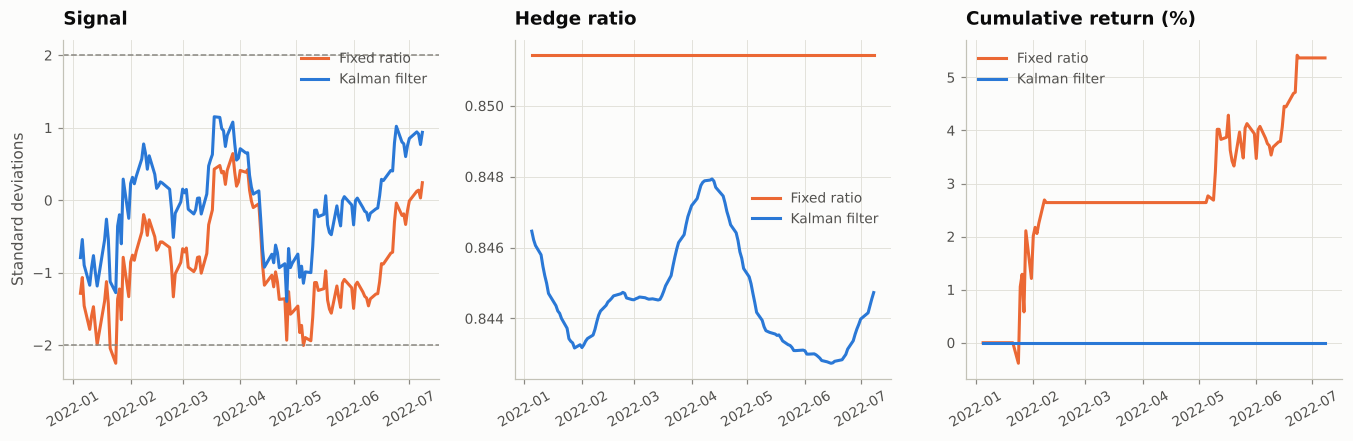

In [7]:
start = prices.index.get_loc(pd.Timestamp("2022-01-06"))
formation, trading = prices[["V", "MA"]].iloc[start - 504:start], prices[["V", "MA"]].iloc[start - 1:start + 126]
static = trade_pair(formation, trading, "static", cost_bps=5)
kalman = trade_pair(formation, trading, "kalman", cost_bps=5)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
axes[0].plot(static.z_score.index, static.z_score, color=ORANGE, label="Fixed ratio")
axes[0].plot(kalman.z_score.index, kalman.z_score, color=BLUE, label="Kalman filter")
for level in (2, -2):
    axes[0].axhline(level, color=MUTED, linestyle="--", linewidth=1.0)
axes[0].set_title("Signal"); axes[0].set_ylabel("Standard deviations"); axes[0].legend()
axes[1].plot(static.hedge_ratio.index, static.hedge_ratio, color=ORANGE, label="Fixed ratio")
axes[1].plot(kalman.hedge_ratio.index, kalman.hedge_ratio, color=BLUE, label="Kalman filter")
axes[1].set_title("Hedge ratio"); axes[1].legend()
axes[2].plot(static.returns.index, 100 * static.returns.cumsum(), color=ORANGE, label="Fixed ratio")
axes[2].plot(kalman.returns.index, 100 * kalman.returns.cumsum(), color=BLUE, label="Kalman filter")
axes[2].set_title("Cumulative return (%)"); axes[2].legend()
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
pd.DataFrame({"Trades": [static.n_trades, kalman.n_trades], "Days in the market": [static.days_in_market, kalman.days_in_market],
              "Total return": [static.returns.sum(), kalman.returns.sum()]}, index=["Fixed ratio", "Kalman filter"])

One pair over one period proves nothing either way: this is an illustration of the mechanics. Whether the approach works is a question for many pairs over many periods, with the pairs chosen before the fact. That is notebook 3.

## Summary

* The rule is simple: enter at 2 standard deviations, exit at 0.5, stop at 4.
* All parameters come from the formation period and positions earn returns from the following day, so the backtest uses no future information. Standardising with data from the traded period turns a losing strategy into an apparently excellent one, which is why this is tested.
* A Kalman filter follows a drifting relation, at the cost of absorbing part of the deviations one wants to trade. Its speed must be clearly slower than the mean reversion of the spread.